# TA Session 6 — Part I: Randomized Controlled Trials
**Econometrics · Barcelona School of Economics** · Lucia Sauer (lucia.sauer@bse.eu)

Contents
1. Potential outcomes: does smoking during pregnancy reduce birthweight? (simulated)
2. ATE, ATT and selection bias
3. Why randomization works
4. An RCT in a ride-hailing app (simulated): design, estimation, balance, covariates, heterogeneous effects (outcome: revenue)
5. Appendix: take-up

No data files needed: everything is simulated in this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

# Course style if available (theme/bse_style.py); otherwise plain matplotlib
try:
    import sys; sys.path.insert(0, "../theme")
    import bse_style; bse_style.apply()
    T_COL, C_COL, PURPLE = bse_style.ORANGE, bse_style.TEAL, bse_style.PURPLE
except ImportError:
    T_COL, C_COL, PURPLE = "#F28627", "#0396A6", "#3E2259"

## 1. Potential outcomes

* $D_i \in \{0,1\}$: treatment. $Y_i(1)$, $Y_i(0)$: outcome with and without treatment.
* Individual effect: $\tau_i = Y_i(1) - Y_i(0)$. We observe only $Y_i = D_iY_i(1) + (1-D_i)Y_i(0)$.

**Example:** does smoking during pregnancy reduce birthweight? We *simulate* the data, so we know **both** potential outcomes for every mother, something we never have in reality.

In the simulation:
* younger mothers are more likely to smoke,
* birthweight without smoking, $Y(0)$, increases with the mother's age,
* smoking lowers birthweight, and the effect is larger for older mothers.

In [2]:
np.random.seed(42)
n = 200
mother_age = np.random.normal(27, 5, n).clip(17, 40)
p_smoke = 1 / (1 + np.exp(-(35 - mother_age) / 2))       # younger mothers smoke more
smoke = np.random.binomial(1, p_smoke)
Y0 = 3000 + 40 * (mother_age - 25) + np.random.normal(0, 150, n)   # birthweight if NOT smoking
Y1 = 2800 + 20 * (mother_age - 25) + np.random.normal(0, 150, n)   # birthweight if smoking
bw = np.where(smoke == 1, Y1, Y0)                                  # what we observe

sim = pd.DataFrame(dict(age=mother_age, smoke=smoke, Y0=Y0, Y1=Y1, bw=bw))
sim = pd.concat([sim[sim.smoke == 1].sample(20, random_state=1),
                 sim[sim.smoke == 0].sample(10, random_state=1)])
sim["cf"] = np.where(sim.smoke == 1, sim.Y0, sim.Y1)               # the counterfactual (unobservable!)
sim.head()

,age,smoke,Y0,Y1,bw,cf
18,22.459880,1,2772.436909,2799.972054,2799.972054,2772.436909
194,27.865905,1,3041.495252,2931.315778,2931.315778,3041.495252
70,28.806978,1,3111.868096,2852.438376,2852.438376,3111.868096
44,19.607390,1,2624.152538,2576.079421,2576.079421,2624.152538
181,22.714212,1,3124.803782,2758.197902,2758.197902,3124.803782


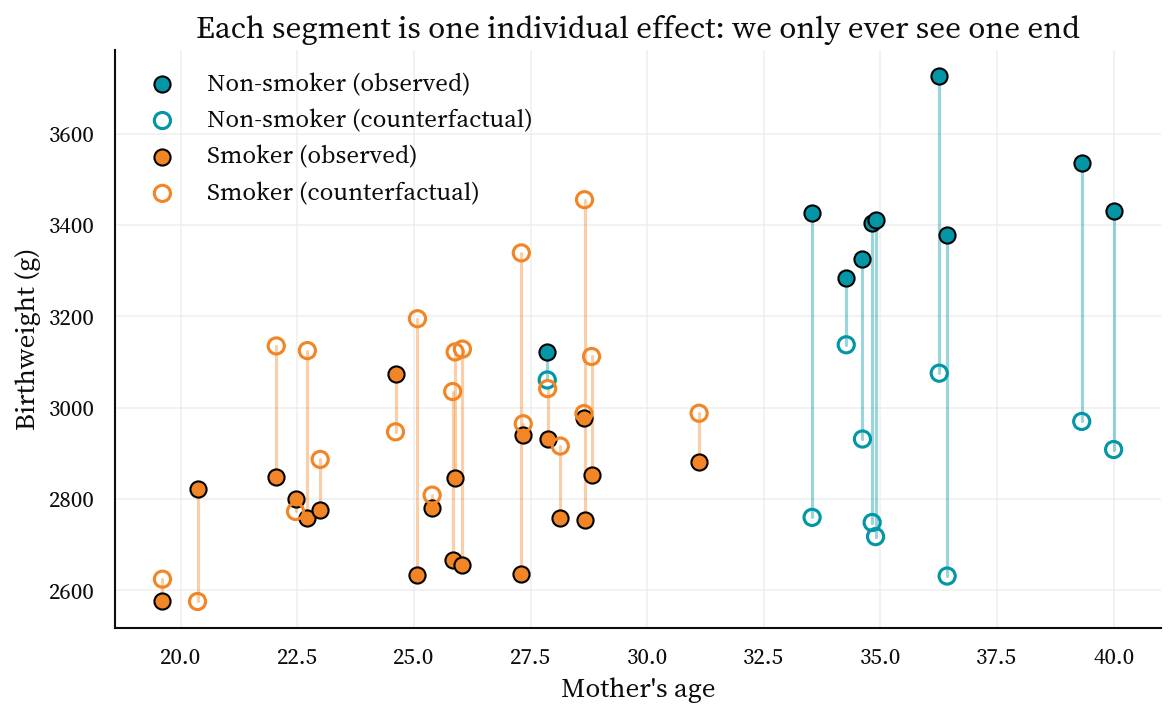

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for _, r in sim.iterrows():
    ax.plot([r.age, r.age], [r.bw, r.cf], color=T_COL if r.smoke else C_COL, alpha=0.4)
for d, col, lab in [(0, C_COL, "Non-smoker"), (1, T_COL, "Smoker")]:
    g = sim[sim.smoke == d]
    ax.scatter(g.age, g.bw, color=col, edgecolor="black", s=60, label=f"{lab} (observed)", zorder=3)
    ax.scatter(g.age, g.cf, facecolor="none", edgecolor=col, s=60, lw=1.5, label=f"{lab} (counterfactual)", zorder=3)
ax.set_xlabel("Mother's age"); ax.set_ylabel("Birthweight (g)")
ax.set_title("Each segment is one individual effect: we only ever see one end")
ax.legend(); plt.show()

## 2. ATE, ATT and selection bias

$$\text{ATE} = E[Y(1) - Y(0)] \qquad \text{ATT} = E[Y(1) - Y(0) \mid D = 1]$$

The naive comparison of means decomposes as

$$\underbrace{E[Y \mid D = 1] - E[Y \mid D = 0]}_{\text{naive comparison}} = \underbrace{E[Y(1) - Y(0) \mid D = 1]}_{\text{ATT}} + \underbrace{E[Y(0) \mid D = 1] - E[Y(0) \mid D = 0]}_{\text{selection bias}}$$

**Age is a confounder.** Younger mothers smoke more, *and* younger mothers have lighter babies anyway (smoking or not, $Y(0)$ increases with age). So $E[Y(0) \mid D = 1] < E[Y(0) \mid D = 0]$: the selection bias is not zero, and the naive comparison is neither the ATT nor the ATE.

## 3. Why randomization works
If $D$ is assigned by a coin flip, $(Y(1), Y(0)) \perp\!\!\!\perp D$, so the selection bias is zero and $E[Y \mid D = 1] - E[Y \mid D = 0] = \text{ATT} = \text{ATE}$.

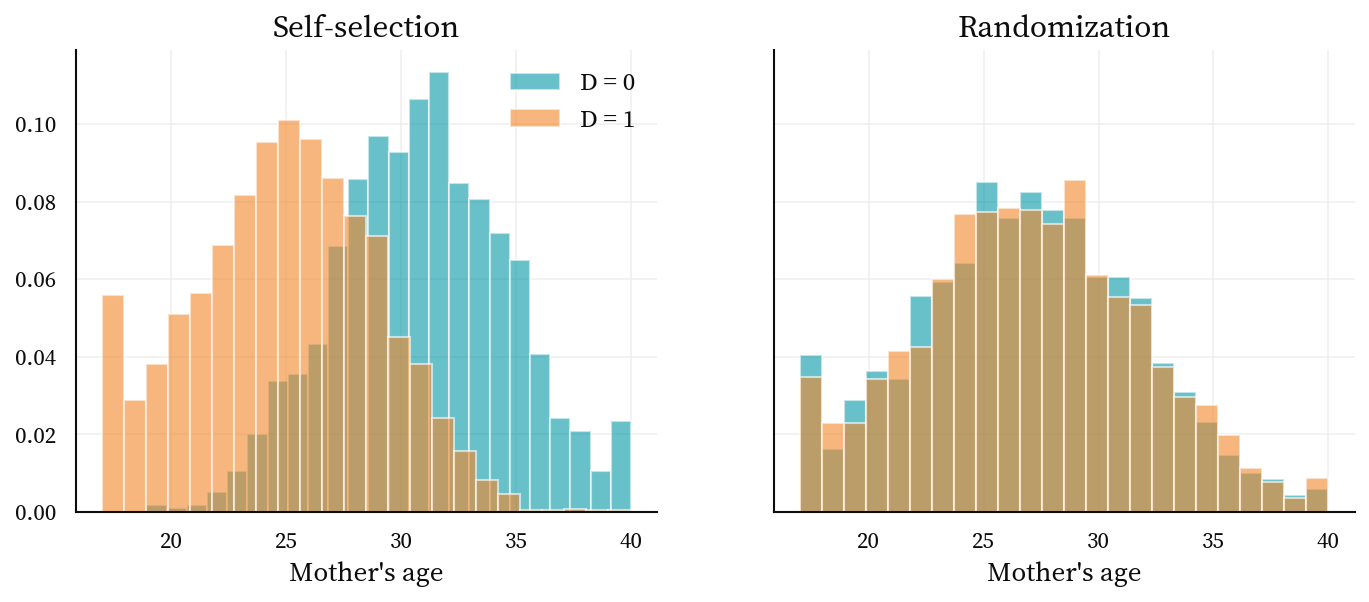

In [4]:
np.random.seed(7)
age_ = np.random.normal(27, 5, 4000).clip(17, 40)
d_self = np.random.binomial(1, 1 / (1 + np.exp(-(30 - age_) / 2.5)))   # mothers choose
d_rand = np.random.binomial(1, 0.5, 4000)                              # coin flip

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, d, ttl in [(axes[0], d_self, "Self-selection"), (axes[1], d_rand, "Randomization")]:
    ax.hist(age_[d == 0], bins=24, density=True, alpha=0.6, color=C_COL, label="D = 0")
    ax.hist(age_[d == 1], bins=24, density=True, alpha=0.6, color=T_COL, label="D = 1")
    ax.set_title(ttl); ax.set_xlabel("Mother's age")
axes[0].legend(); plt.show()

⚠️ **Caveat.** In this example randomization is not an option: assigning pregnant women to smoke would be unethical (and infeasible). For questions like this we need observational methods: matching, IV, RDD, DiD (the next TAs).

## 4. An RCT in a ride-hailing app

*Ryde* (a fictional ride-hailing app) wants to add **one** new option to the menu: **"Wait & Save"**, about 25% cheaper if you accept being picked up in 10–15 minutes.

**Hypothesis:** price-sensitive users who today take the bus or walk will now request a ride ⇒ more rides. But every "Wait & Save" ride is cheaper, and some users will switch from Economy ⇒ the effect on **revenue** is ambiguous. That is why we run the experiment.

In industry, an RCT like this one is called an **A/B test** (A = current app, B = app with the new option).

**Design**
* **Outcome** $Y_i$ = `revenue_post`: revenue (€) from user $i$ in the 4 weeks of the test (rides × price). Not the number of rides: rides may go up while revenue goes down.
* **Treatment** $D_i$ = `treat`: 1 if user $i$ sees app B (with "Wait & Save"), 0 if app A.
* **Units:** active users, each assigned to A or B with probability ½ (a coin flip per user).
* Pre-treatment covariates $X_i$: `city`, `age`, `tenure` (months on the app), `rides_pre` and `revenue_pre` (rides and € spent in the 4 weeks *before* the test).

### 4.1 Simulating the data
We generate the data ourselves, so we know both potential outcomes for every user and hence the **true** ATE. In the simulation:
* each user has a usual fare (higher in London and Paris); past rides depend on city, age and tenure;
* only some users would pick "Wait & Save" if offered (heavy and young users more often);
* those users (i) take **new** rides at 75% of their fare (more new rides in London/Paris than in Madrid), and (ii) **switch** about half of their usual rides to the cheaper option (−25% each): cannibalization;
* revenue with app B = revenue with app A − lost revenue from switched rides + revenue from new rides.

In [5]:
CITIES = ["Madrid", "Barcelona", "Paris", "London"]

def simulate_app(n=4000, seed=669):
    rng = np.random.default_rng(seed)
    # pre-treatment covariates
    city = rng.choice(CITIES, n, p=[0.3, 0.3, 0.2, 0.2])
    age = np.clip(rng.normal(34, 9, n).round(), 18, 70).astype(int)
    tenure = np.clip(rng.exponential(20, n).round(), 1, 96).astype(int)           # months on the app
    base = pd.Series(city).map({"Madrid": 3.0, "Barcelona": 3.5, "Paris": 4.5, "London": 5.5}).values
    fare = pd.Series(city).map({"Madrid": 11, "Barcelona": 12, "Paris": 16, "London": 19}).values \
        * rng.lognormal(0, 0.15, n)                                                 # user's usual fare (€)
    mu_pre = base * np.exp(-0.02 * (age - 34)) * (0.7 + 0.6 * np.minimum(tenure, 48) / 48)
    rides_pre = rng.poisson(mu_pre * rng.gamma(1.5, 1 / 1.5, n))                   # rides in the 4 weeks before
    revenue_pre = np.round(rides_pre * fare * rng.uniform(0.9, 1.1, n), 2)         # € spent in the 4 weeks before
    # random assignment
    treat = rng.binomial(1, 0.5, n)
    # would the user pick "Wait & Save" if offered? (heavy and young users more likely)
    p_choose = 1 / (1 + np.exp(-(-0.4 + 0.15 * (rides_pre - 4) - 0.04 * (age - 34))))
    would_choose = rng.binomial(1, p_choose)
    # potential outcomes in the 4 weeks of the test
    tau = np.clip(pd.Series(city).map({"Madrid": 0.3, "Barcelona": 0.8, "Paris": 1.8, "London": 3.0}).values
                  + 0.03 * (34 - age), 0, None)                                    # extra rides from the new option
    rides0 = rng.poisson(0.8 * rides_pre + 0.02 * tenure + 0.5)                    # rides with app A
    new_rides = rng.poisson(tau) * would_choose                                    # NEW rides, at 75% of the fare
    switched = rng.binomial(rides0, 0.5) * would_choose                            # usual rides switched to W&S (-25%)
    rev0 = rides0 * fare                                                           # revenue with app A
    rev1 = rev0 - 0.25 * fare * switched + 0.75 * fare * new_rides                 # revenue with app B
    # what we observe
    rides_post = np.where(treat == 1, rides0 + new_rides, rides0)
    revenue_post = np.round(np.where(treat == 1, rev1, rev0), 2)
    df = pd.DataFrame(dict(user_id=np.arange(1, n + 1), city=city, age=age, tenure=tenure,
                           rides_pre=rides_pre, revenue_pre=revenue_pre, treat=treat,
                           chose_wait_save=treat * would_choose, rides_post=rides_post,
                           revenue_post=revenue_post))
    return df, pd.DataFrame(dict(rev0=rev0, rev1=rev1))

app, truth = simulate_app()
app["city"] = pd.Categorical(app.city, categories=CITIES)   # Madrid = base category
print(f"True ATE (we only know it because we simulated): {(truth.rev1 - truth.rev0).mean():.2f} €")
app.head()

True ATE (we only know it because we simulated): 3.08 €


,user_id,city,age,tenure,rides_pre,revenue_pre,treat,chose_wait_save,rides_post,revenue_post
0,1,Madrid,37,15,5,48.86,0,0,1,9.25
1,2,Madrid,33,35,7,83.38,0,0,9,114.59
2,3,London,35,9,6,117.30,1,0,6,115.93
3,4,Madrid,18,11,0,0.00,1,0,1,12.67
4,5,London,33,27,15,329.65,1,1,15,270.34


### 4.2 ATE = difference in means
Randomization ⇒ no selection bias ⇒ $\text{ATE} = E[Y \mid D = 1] - E[Y \mid D = 0]$, estimated by $\bar Y_1 - \bar Y_0$.

**Test:** $H_0: E[Y \mid D = 1] = E[Y \mid D = 0]$ vs $H_a: E[Y \mid D = 1] \neq E[Y \mid D = 0]$, with the Welch statistic
$$t = \frac{\bar Y_1 - \bar Y_0}{\sqrt{s_1^2/n_1 + s_0^2/n_0}} \overset{H_0}{\approx} N(0,1).$$
Reject at 5% if $|t| > 1.96$.

In [6]:
y1 = app.loc[app.treat == 1, "revenue_post"]   # D = 1 (app B)
y0 = app.loc[app.treat == 0, "revenue_post"]   # D = 0 (app A)
print(app.groupby("treat")["revenue_post"].agg(["count", "mean", "std"]).round(2))
diff = y1.mean() - y0.mean()
se = np.sqrt(y1.var() / len(y1) + y0.var() / len(y0))
print(f"\nDifference in means = {diff:.2f} €,  SE = {se:.2f},  t = {diff / se:.2f}")
res = stats.ttest_ind(y1, y0, equal_var=False)     # same test with scipy (Welch)
print(f"scipy: t = {res.statistic:.3f}, p-value = {res.pvalue:.4f}, df = {res.df:.1f}")

       count   mean    std
treat                     
0       1954  57.65  61.39
1       2046  60.88  65.35

Difference in means = 3.23 €,  SE = 2.00,  t = 1.61
scipy: t = 1.612, p-value = 0.1070, df = 3996.9


### 4.3 … which is the same as a regression on $D$
$$\text{revenue\_post}_i = \beta_0 + \beta_1 D_i + \varepsilon_i$$
$\hat\beta_0$ = mean in control, $\hat\beta_1$ = difference in means.

In [7]:
r1 = smf.ols("revenue_post ~ treat", data=app).fit(cov_type="HC1")     # robust (HC1) SEs
print(r1.summary())

                            OLS Regression Results                            
Dep. Variable:           revenue_post   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     2.599
Date:                Sun, 08 Nov 2026   Prob (F-statistic):              0.107
Time:                        23:32:54   Log-Likelihood:                -22276.
No. Observations:                4000   AIC:                         4.456e+04
Df Residuals:                    3998   BIC:                         4.457e+04
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     57.6523      1.389     41.513      0.0

### 4.4 Are treatment and control truly random? (balance check)
For each **pre-treatment** covariate $X_k$, test $H_0: E[X_k \mid D = 1] = E[X_k \mid D = 0]$ with a difference-in-means $t$-test.
With many tests, about 1 in 20 rejects at 5% just by chance.

In [8]:
app_d = pd.get_dummies(app, columns=["city"], dtype=int)
check = ["age", "tenure", "rides_pre", "revenue_pre", "city_Madrid", "city_Barcelona", "city_Paris", "city_London"]
rows = []
for v in check:
    a, b = app_d.loc[app_d.treat == 1, v], app_d.loc[app_d.treat == 0, v]
    t_ = stats.ttest_ind(a, b, equal_var=False)
    rows.append([v, a.mean(), b.mean(), a.mean() - b.mean(), t_.statistic, t_.pvalue])
display(pd.DataFrame(rows, columns=["variable", "B", "A", "diff", "t", "p-value"]).round(3))

# Joint check: do the covariates predict treatment? (H0: all slopes = 0)
joint = smf.ols("treat ~ age + tenure + rides_pre + revenue_pre + C(city)", data=app).fit()
print(f"Joint F-test: F = {joint.fvalue:.2f}, p = {joint.f_pvalue:.3f}")

,variable,B,A,diff,t,p-value
0,age,33.767,33.912,-0.145,-0.527,0.599
1,tenure,19.747,20.278,-0.531,-0.880,0.379
2,rides_pre,3.832,3.815,0.018,0.138,0.890
3,revenue_pre,56.614,56.286,0.328,0.154,0.878
4,city_Madrid,0.298,0.295,0.003,0.233,0.816
5,city_Barcelona,0.297,0.303,-0.007,-0.469,0.639
6,city_Paris,0.209,0.203,0.006,0.472,0.637
7,city_London,0.196,0.199,-0.003,-0.206,0.837


Joint F-test: F = 0.21, p = 0.983


### 4.5 Using covariates to estimate the ATE
$$\text{revenue\_post}_i = \beta_0 + \beta_1 D_i + \gamma_1\,\text{age}_i + \gamma_2\,\text{tenure}_i + \gamma_3\,\text{revenue\_pre}_i + \textstyle\sum_c \delta_c\,\text{city}_{c,i} + \varepsilon_i$$

Randomization makes $D$ independent of $X$, so the controls do **not** change the estimate (there is no bias to remove), but they absorb residual variance → **smaller SE**. Only pre-treatment covariates!

In [9]:
r3 = smf.ols("revenue_post ~ treat + C(city) + age + tenure + revenue_pre", data=app).fit(cov_type="HC1")
print(r3.summary())

                            OLS Regression Results                            
Dep. Variable:           revenue_post   R-squared:                       0.781
Model:                            OLS   Adj. R-squared:                  0.780
Method:                 Least Squares   F-statistic:                     649.2
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:32:54   Log-Likelihood:                -19242.
No. Observations:                4000   AIC:                         3.850e+04
Df Residuals:                    3992   BIC:                         3.855e+04
Df Model:                           7                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                5.2620 

,(1) no controls,"(2) + city, age, tenure",(3) + revenue before
coef treat,3.231,3.496,3.096
robust s.e.,2.004,1.775,0.939
p-value,0.107,0.049,0.001
R2,0.001,0.218,0.781


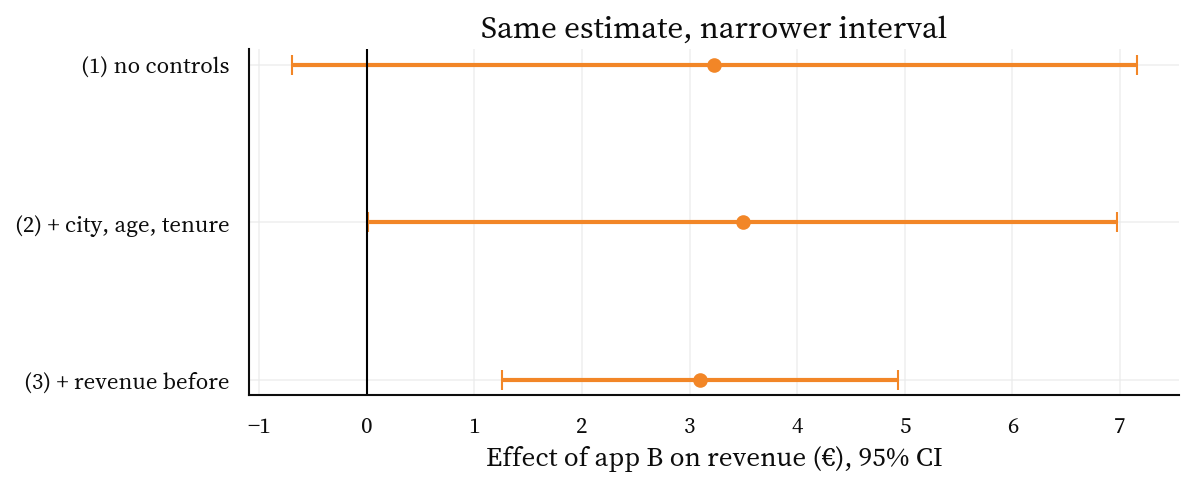

In [10]:
specs = {"(1) no controls":          "revenue_post ~ treat",
         "(2) + city, age, tenure":  "revenue_post ~ treat + C(city) + age + tenure",
         "(3) + revenue before":     "revenue_post ~ treat + C(city) + age + tenure + revenue_pre"}
res = {k: smf.ols(f, data=app).fit(cov_type="HC1") for k, f in specs.items()}
display(pd.DataFrame({k: [r.params.treat, r.bse.treat, r.pvalues.treat, r.rsquared] for k, r in res.items()},
                     index=["coef treat", "robust s.e.", "p-value", "R2"]).round(3))

fig, ax = plt.subplots(figsize=(8, 3))
for k, (lab, r) in enumerate(res.items()):
    b, se = r.params.treat, r.bse.treat
    ax.errorbar(b, k, xerr=1.96 * se, fmt="o", color=T_COL, capsize=5, lw=2)
ax.set_yticks(range(3)); ax.set_yticklabels(res.keys()); ax.invert_yaxis()
ax.axvline(0, color="black", lw=1); ax.set_xlabel("Effect of app B on revenue (€), 95% CI")
ax.set_title("Same estimate, narrower interval"); plt.show()

**Why does $\hat\beta_1$ still move a little?** Randomization guarantees balance *in expectation*, not in every sample. In OLS the omitted-variable formula holds exactly:
$$\hat\beta_1^{\text{no controls}} - \hat\beta_1^{\text{controls}} = \sum_k \hat\gamma_k\,(\bar X_{k,1} - \bar X_{k,0})$$
Small chance imbalances in $ that predict $ explain the (small) change. Both estimators are unbiased.

In [11]:
fs = smf.ols("revenue_post ~ treat", data=app).fit()
fl = smf.ols("revenue_post ~ treat + C(city) + age + tenure + revenue_pre", data=app).fit()
X = pd.DataFrame(fl.model.exog, columns=fl.model.exog_names)
D = app.treat.values
dec = pd.DataFrame({"gamma": fl.params.drop(["Intercept", "treat"])})
dec["diff_X"] = [X.loc[D == 1, v].mean() - X.loc[D == 0, v].mean() for v in dec.index]
dec["contribution"] = dec.gamma * dec.diff_X
display(dec.round(3))
print(f"sum of contributions = {dec.contribution.sum():.4f}")
print(f"beta(no controls) - beta(controls) = {fs.params.treat - fl.params.treat:.4f}")

,gamma,diff_X,contribution
C(city)[T.Barcelona],2.329,-0.007,-0.016
C(city)[T.Paris],8.118,0.006,0.049
C(city)[T.London],15.866,-0.003,-0.041
age,-0.053,-0.145,0.008
tenure,0.228,-0.531,-0.121
revenue_pre,0.783,0.328,0.257


sum of contributions = 0.1352
beta(no controls) - beta(controls) = 0.1352


### 4.6 Heterogeneous treatment effects by city
$$\text{revenue\_post}_i = \beta_0 + \beta_1 D_i + \sum_{c\neq\text{Madrid}} \delta_c\,\text{city}_{c,i} + \sum_{c\neq\text{Madrid}} \theta_c\,(D_i\times\text{city}_{c,i}) + \varepsilon_i$$

* $\beta_1$ = effect in Madrid (base city); $\theta_c$ = how much larger the effect is in city $c$.
* Effect in city $c$ = $\beta_1 + \theta_c$. $H_0$: same effect everywhere ⇔ all $\theta_c = 0$.

In [12]:
hte = smf.ols("revenue_post ~ treat * C(city)", data=app).fit(cov_type="HC1")
print(hte.summary())

                            OLS Regression Results                            
Dep. Variable:           revenue_post   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.175
Method:                 Least Squares   F-statistic:                     84.81
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          2.13e-115
Time:                        23:32:54   Log-Likelihood:                -21889.
No. Observations:                4000   AIC:                         4.379e+04
Df Residuals:                    3992   BIC:                         4.385e+04
Df Model:                           7                                         
Covariance Type:                  HC1                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

Madrid     effect =   -4.12 €  (se 2.02)
Barcelona  effect =    4.04 €  (se 2.37)
Paris      effect =    6.18 €  (se 4.34)
London     effect =   10.18 €  (se 6.51)
<F test: F=3.7900570363351633, p=0.009951292729069847, df_denom=3.99e+03, df_num=3>


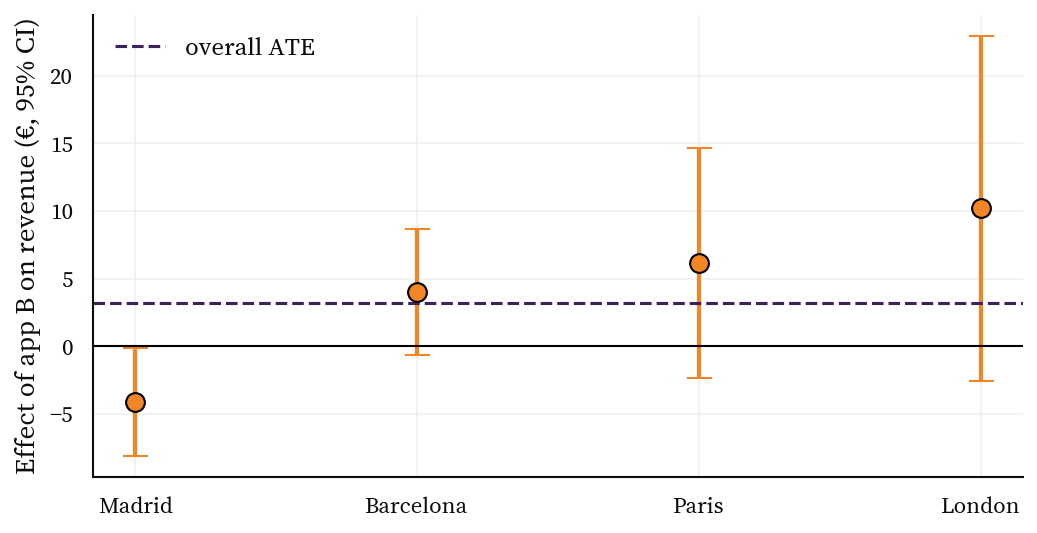

In [13]:
# Effect in each city = treat + treat:city
names = list(hte.params.index)
city_eff = []
for c in CITIES:
    L = np.zeros(len(names)); L[names.index("treat")] = 1
    if c != "Madrid":
        L[names.index(f"treat:C(city)[T.{c}]")] = 1
    t_ = hte.t_test(L)
    city_eff.append((c, float(t_.effect[0]), float(np.squeeze(t_.sd))))
    print(f"{c:10s} effect = {city_eff[-1][1]:7.2f} €  (se {city_eff[-1][2]:.2f})")

# H0: the effect is the same in all cities
print(hte.f_test("treat:C(city)[T.Barcelona] = 0, treat:C(city)[T.Paris] = 0, treat:C(city)[T.London] = 0"))

fig, ax = plt.subplots(figsize=(8, 4))
for k, (c, b, se) in enumerate(city_eff):
    ax.errorbar(k, b, yerr=1.96 * se, fmt="o", ms=9, color=T_COL, mec="black", capsize=6, lw=2)
ax.axhline(0, color="black", lw=1)
ax.axhline(r1.params.treat, color=PURPLE, ls="--", label="overall ATE")
ax.set_xticks(range(len(CITIES))); ax.set_xticklabels(CITIES)
ax.set_ylabel("Effect of app B on revenue (€, 95% CI)"); ax.legend(); plt.show()

In Madrid the effect is negative: users mostly switch to the cheaper option instead of riding more (cannibalization), so revenue falls.

## Appendix A: take-up
Not every user in B chooses "Wait & Save". The coefficient on `treat` is the **ITT** (the effect of *offering* the option). Comparing choosers vs non-choosers would be biased: heavy users self-select into choosing it.

In [14]:
takeup = app.loc[app.treat == 1, "chose_wait_save"].mean()
itt = r3.params.treat
print(f"Take-up = {takeup:.2f};  ITT = {itt:.2f} €;  effect on those who chose it ≈ ITT / take-up = {itt / takeup:.2f} €")

# The biased comparison (within B): choosers already spent much more BEFORE the test
app[app.treat == 1].groupby("chose_wait_save")[["revenue_pre", "revenue_post"]].mean().round(2)

Take-up = 0.39;  ITT = 3.10 €;  effect on those who chose it ≈ ITT / take-up = 7.85 €


,revenue_pre,revenue_post
chose_wait_save,,
0,40.71,45.25
1,81.04,84.89
